Experiment No. 2 
Experiment Name 
Contrast Enhancement and Histogram-Based Image Processing using Python and OpenCV 
 
Aim 
To analyze and implement contrast enhancement techniques using histogram analysis and 
histogram equalization in Python and OpenCV for improving image quality and enhancing 
visual information in low-contrast images. 
 
Purpose 
Image contrast plays a significant role in the performance of computer vision systems. Poor 
illumination,  sensor  limitations,  or  environmental  conditions  often  result  in  low-contrast 
images,  making  feature  extraction  and  object  recognition  difficult.  Histogram-based 
enhancement techniques improve the distribution of pixel intensities, thereby enhancing image 
visibility and facilitating subsequent image analysis tasks. 
In  this  experiment,  students  will  implement  contrast  stretching,  histogram  analysis,  and 
histogram equalization using Python and OpenCV. The effectiveness of these enhancement 
techniques will be evaluated on real-world images such as medical images, satellite images, or 
low-light photographs. 
 
Prerequisites 
• Basic knowledge of digital image processing 
• Familiarity with Python programming 
• Python libraries: OpenCV (cv2), NumPy, Matplotlib 
• Understanding of grayscale images and pixel intensity distributions 
• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps 
1. Import the required libraries, including OpenCV, NumPy, and Matplotlib. 
2. Load  a  low-contrast  grayscale  image  or convert  a  color  image  into  grayscale  for 
processing. 
3. Display the original image and generate its histogram to analyze the distribution of 
pixel intensity values. 
4. Perform contrast stretching to improve the dynamic range of pixel intensities.
5. Apply Histogram Equalization using OpenCV and compare the enhanced image with 
the original image. 
6. Implement Contrast Limited Adaptive Histogram Equalization (CLAHE) and observe 
its performance on images with varying illumination. 
7. Plot and compare the histograms of the original, histogram-equalized, and CLAHE-
enhanced images. 
8. Analyze the visual improvements in terms of brightness, contrast, and feature visibility. 
9. Compare the effectiveness of Histogram Equalization and CLAHE for different types 
of images. 
10. Document the observations and discuss the role of histogram-based enhancement in 
computer vision applications.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

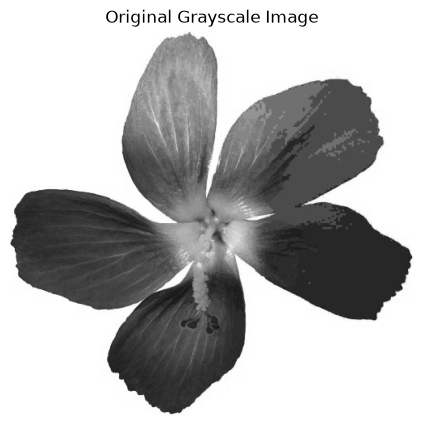

In [3]:
image_path = Path("sample.jpg")  # Change this to your image path

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 5))
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

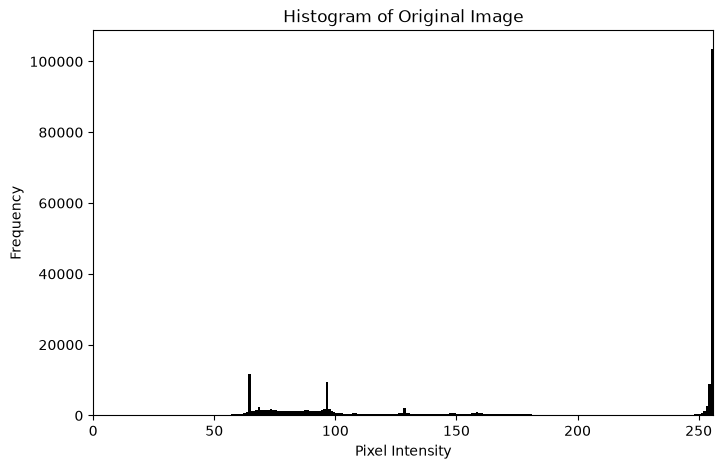

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(gray_image.ravel(), bins=256, range=(0, 256), color="black")
plt.title("Histogram of Original Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.show()

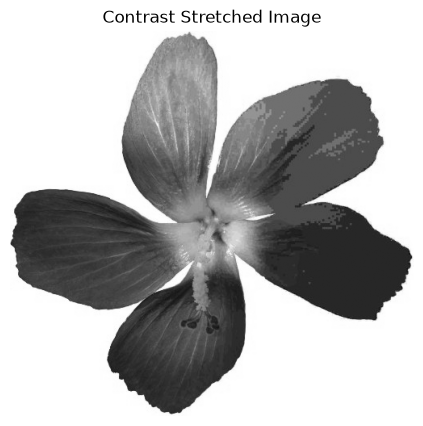

In [5]:
minimum_intensity = np.min(gray_image)
maximum_intensity = np.max(gray_image)

if maximum_intensity == minimum_intensity:
    stretched_image = gray_image.copy()
else:
    stretched_image = cv2.normalize(
        gray_image,
        None,
        alpha=0,
        beta=255,
        norm_type=cv2.NORM_MINMAX
    )

plt.figure(figsize=(8, 5))
plt.imshow(stretched_image, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")
plt.show()

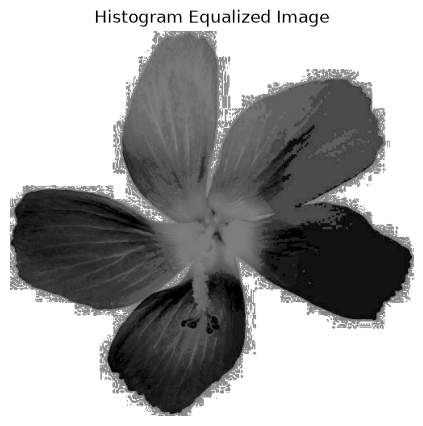

In [7]:
equalized_image = cv2.equalizeHist(gray_image)

plt.figure(figsize=(8, 5))
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")
plt.show()

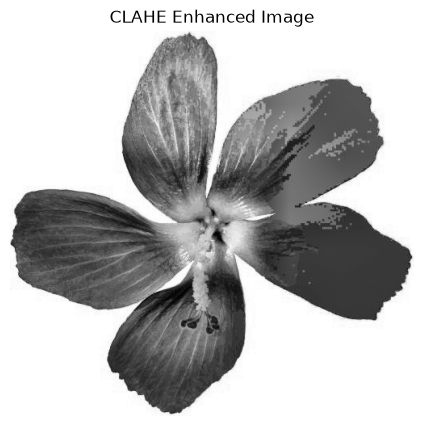

In [8]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(gray_image)

plt.figure(figsize=(8, 5))
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE Enhanced Image")
plt.axis("off")
plt.show()

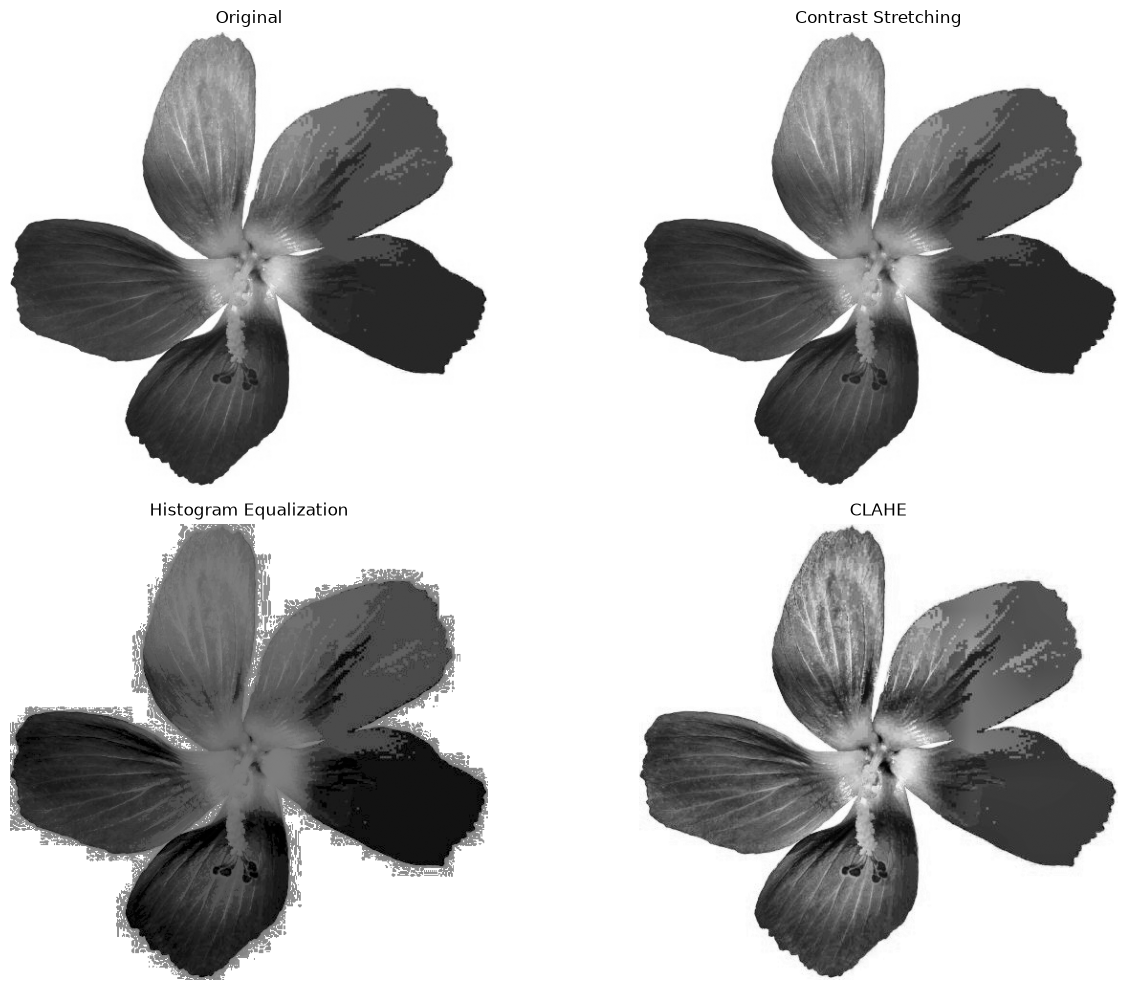

In [9]:
images = [
    gray_image,
    stretched_image,
    equalized_image,
    clahe_image
]

titles = [
    "Original",
    "Contrast Stretching",
    "Histogram Equalization",
    "CLAHE"
]

plt.figure(figsize=(14, 10))

for index, (current_image, title) in enumerate(zip(images, titles)):
    plt.subplot(2, 2, index + 1)
    plt.imshow(current_image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

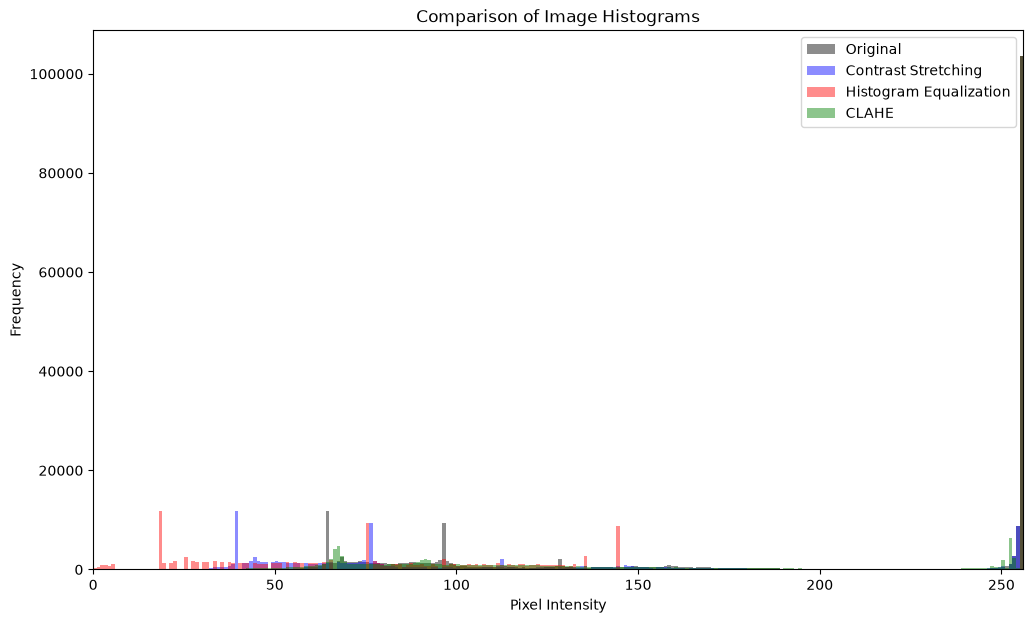

In [10]:
colors = ["black", "blue", "red", "green"]

plt.figure(figsize=(12, 7))

for current_image, title, color in zip(images, titles, colors):
    plt.hist(
        current_image.ravel(),
        bins=256,
        range=(0, 256),
        color=color,
        alpha=0.45,
        label=title
    )

plt.title("Comparison of Image Histograms")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.legend()
plt.show()

In [11]:
for current_image, title in zip(images, titles):
    print(title)
    print(f"Minimum intensity: {np.min(current_image)}")
    print(f"Maximum intensity: {np.max(current_image)}")
    print(f"Mean intensity: {np.mean(current_image):.2f}")
    print(f"Standard deviation: {np.std(current_image):.2f}")
    print("-" * 40)

Original
Minimum intensity: 29
Maximum intensity: 255
Mean intensity: 179.25
Standard deviation: 80.13
----------------------------------------
Contrast Stretching
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 169.53
Standard deviation: 90.44
----------------------------------------
Histogram Equalization
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 152.47
Standard deviation: 95.02
----------------------------------------
CLAHE
Minimum intensity: 13
Maximum intensity: 255
Mean intensity: 179.66
Standard deviation: 80.32
----------------------------------------


In [12]:
output_directory = Path("enhanced_outputs")
output_directory.mkdir(exist_ok=True)

cv2.imwrite(str(output_directory / "original_grayscale.png"), gray_image)
cv2.imwrite(str(output_directory / "contrast_stretched.png"), stretched_image)
cv2.imwrite(str(output_directory / "histogram_equalized.png"), equalized_image)
cv2.imwrite(str(output_directory / "clahe_enhanced.png"), clahe_image)

print(f"Enhanced images saved in: {output_directory.resolve()}")

Enhanced images saved in: /home/harshit/College_WORK/Computer-Vision-Lab-2026-27-ODD-Sem-3rd-Year-Section-C/Experiment 2 - Solutions by students/labsheet-2-Harshit-Dubey-Section-c-CU24250109/enhanced_outputs


In [13]:
observations = """
Observations:

1. The original image has a limited range of pixel intensities, indicating low contrast.
2. Contrast stretching expands the intensity range and improves the overall contrast.
3. Histogram equalization redistributes pixel intensities across the available range.
4. Histogram equalization may over-enhance noise in some regions.
5. CLAHE improves local contrast while limiting excessive enhancement.
6. CLAHE generally performs better than global histogram equalization for images
   containing varying illumination.
7. Histogram-based enhancement improves visibility and can assist later computer
   vision tasks such as segmentation, feature extraction, and object recognition.
"""

print(observations)


Observations:

1. The original image has a limited range of pixel intensities, indicating low contrast.
2. Contrast stretching expands the intensity range and improves the overall contrast.
3. Histogram equalization redistributes pixel intensities across the available range.
4. Histogram equalization may over-enhance noise in some regions.
5. CLAHE improves local contrast while limiting excessive enhancement.
6. CLAHE generally performs better than global histogram equalization for images
   containing varying illumination.
7. Histogram-based enhancement improves visibility and can assist later computer
   vision tasks such as segmentation, feature extraction, and object recognition.



Questions 
1. What is image contrast, and why is it important in image processing? 
2. Explain the concept of an image histogram. What information does it provide? 
3. Differentiate between Histogram Stretching and Histogram Equalization. 
4. What is Contrast Limited Adaptive Histogram Equalization (CLAHE)? How does it 
differ from standard Histogram Equalization? 
5. Why is histogram equalization commonly applied before feature extraction and image 
segmentation? 
6. Mention three real-world applications where histogram equalization is widely used. 
7. What are the limitations of global histogram equalization? 
8. How does contrast enhancement improve the performance of object detection and 
recognition systems? 
9. Compare  histogram-based  enhancement  techniques  with  brightness  adjustment 
methods. 
10. Why is CLAHE preferred for medical imaging and low-light image enhancement? 

Here are clear, exam-ready answers:

### 1. What is image contrast, and why is it important in image processing?

**Image contrast** is the difference in intensity or brightness between different regions of an image. High-contrast images have clearly distinguishable bright and dark areas, while low-contrast images appear dull or faded.

**Importance:**

* Improves visibility of objects and details.
* Makes edges and boundaries more distinct.
* Helps in image analysis, segmentation, and feature extraction.
* Improves the performance of computer vision systems.

### 2. Explain the concept of an image histogram. What information does it provide?

An **image histogram** is a graphical representation of the distribution of pixel intensity values in an image.

For a grayscale image, the horizontal axis represents intensity values (usually **0–255**) and the vertical axis represents the number of pixels having each intensity.

It provides information about:

* Brightness distribution.
* Contrast of the image.
* Presence of dark or bright regions.
* Whether the image is underexposed or overexposed.
* The range of intensity values used.

### 3. Differentiate between Histogram Stretching and Histogram Equalization.

| Histogram Stretching                                | Histogram Equalization                                               |
| --------------------------------------------------- | -------------------------------------------------------------------- |
| Expands the existing intensity range.               | Redistributes pixel intensities to produce a more uniform histogram. |
| Usually uses a linear transformation.               | Uses the cumulative distribution function (CDF).                     |
| Preserves the general shape of the histogram.       | Changes the shape of the histogram.                                  |
| Simple and predictable.                             | Usually provides stronger contrast enhancement.                      |
| Useful when intensity values occupy a narrow range. | Useful when pixel intensities are unevenly distributed.              |

### 4. What is CLAHE? How does it differ from standard Histogram Equalization?

**CLAHE (Contrast Limited Adaptive Histogram Equalization)** is a local contrast-enhancement technique. It divides an image into small regions called **tiles**, performs histogram equalization on each region, and limits excessive amplification of noise using a **clip limit**.

**Difference from standard Histogram Equalization:**

* Standard HE works on the **entire image globally**.
* CLAHE works on **small local regions**.
* Standard HE can over-enhance noise and lose local details.
* CLAHE limits contrast amplification and generally preserves local details better.
* CLAHE is particularly effective when illumination varies across an image.

### 5. Why is histogram equalization commonly applied before feature extraction and image segmentation?

Histogram equalization improves the contrast of an image, making important structures, edges, and boundaries easier to distinguish.

As a result:

* Features become more prominent.
* Edge detection becomes more reliable.
* Similar objects become easier to separate.
* Segmentation algorithms can distinguish regions more effectively.
* Feature extraction algorithms can obtain more meaningful characteristics.

### 6. Mention three real-world applications where histogram equalization is widely used.

Three common applications are:

1. **Medical imaging** – enhancing X-rays, CT scans, and other images to reveal structures.
2. **Satellite and remote-sensing images** – improving visibility of geographical features.
3. **Surveillance and photography** – enhancing images captured in poor lighting conditions.

### 7. What are the limitations of global histogram equalization?

Global histogram equalization has several limitations:

* It considers the **whole image**, so it may not enhance local details effectively.
* It can **over-enhance noise**.
* It may make some regions too bright or too dark.
* It can cause unnatural-looking images.
* It does not perform well when different parts of an image have very different illumination.
* It may distort the original brightness characteristics of the image.

### 8. How does contrast enhancement improve the performance of object detection and recognition systems?

Contrast enhancement makes objects and their boundaries more distinguishable from the background.

This can:

* Make important features more visible.
* Improve edge and shape detection.
* Help algorithms detect objects in low-light or poorly exposed images.
* Improve the quality of features used by machine-learning models.
* Increase detection and recognition accuracy in challenging lighting conditions.

### 9. Compare histogram-based enhancement techniques with brightness adjustment methods.

| Histogram-Based Enhancement                        | Brightness Adjustment                                                                       |
| -------------------------------------------------- | ------------------------------------------------------------------------------------------- |
| Changes the distribution of pixel intensities.     | Mainly shifts pixel intensities brighter or darker.                                         |
| Can improve **contrast** as well as visibility.    | Primarily changes overall brightness.                                                       |
| Includes histogram stretching, HE, and CLAHE.      | Usually involves adding/subtracting an intensity value or applying a simple transformation. |
| Can reveal details hidden in low-contrast regions. | May not improve contrast between objects and background.                                    |
| More suitable for complex contrast problems.       | Simple and useful for basic exposure correction.                                            |

### 10. Why is CLAHE preferred for medical imaging and low-light image enhancement?

CLAHE is preferred because it improves **local contrast** while limiting excessive amplification of noise.

In medical and low-light images:

* Important details may be present only in small regions.
* Illumination can vary significantly across the image.
* Noise can be amplified by ordinary histogram equalization.
* CLAHE enhances local structures while controlling noise amplification.

Therefore, CLAHE can reveal subtle details such as tissue structures in medical images or objects in dark scenes **without excessively distorting the image**.
